# AIP304 CW2 Option 2 | Formal experiment

Can lesion supervision during training help a classifier reject unseen diseases on familiar plants while retaining its ability to classify known diseases? This experiment compares a ResNet-18 baseline with the same classifier trained using an auxiliary lesion prediction loss.

The protocol was recorded after the pilot and before the formal training runs. The primary outcome is familiar-host test AUOSCR. Evidence supports the hypothesis if each assignment shows a mean gain of at least 0.02, a positive paired difference for at least two of three seeds, and a mean known-class macro-F1 loss of at most 0.02. The pilot is documented in `Predict.ipynb`.

## Data and protocol

Use PlantSeg v7 with the supplied train, validation and test partitions. The earlier exact RGB audit and the reviewed cross-partition near-duplicate audit determine the formal image inventory. Candidate generation uses luminance correlation, perceptual and difference hashes, crop and mirror variants, and source URL matches. Visual review confirms same-source photographs. Consistent-label groups retain one representative in its original partition. Conflicting-label groups are excluded. Severe edits can evade screening. See `artifacts/near_duplicate_audit/README.md` for the audit and its reproduction steps. Assignment A holds out the first and second alphabetically sorted disease classes of each familiar host for validation and test, respectively. Assignment B holds out the second and third. Citrus and potato serve as unfamiliar-host validation and test controls. Both methods use the same frozen inventory and class assignments.

Open this notebook from the project directory. Use the Python environment with PyTorch, torchvision, Pillow, NumPy, and Matplotlib. Set `PLANTSEG_ROOT` to the extracted PlantSeg v7 directory containing `Metadata.csv`, or put the directory at `data/plantseg`. The full local experiment uses the accompanying Python modules and audit records.

In [1]:
from collections import Counter
from hashlib import sha256
import json
import os
from pathlib import Path

from formal_manifest import freeze_manifest

FORMAL_DIR = Path("artifacts/formal")
PROTOCOL_PATH = FORMAL_DIR / "protocol.json"
MANIFEST_PATH = FORMAL_DIR / "manifest.json"
CHECKPOINT_DIR = FORMAL_DIR / "checkpoints"
EVALUATION_DIR = FORMAL_DIR / "evaluation"
DATA_ROOT = Path(os.environ.get("PLANTSEG_ROOT", "data/plantseg"))

protocol = json.loads(PROTOCOL_PATH.read_text())
manifest = freeze_manifest(
    "artifacts/option2_manifest.json",
    "artifacts/near_duplicate_audit/decisions.json",
    DATA_ROOT,
    MANIFEST_PATH,
)
print("Protocol SHA-256:", sha256(PROTOCOL_PATH.read_bytes()).hexdigest())
print("Audit:", manifest["formal_audit"])
for assignment, rows in manifest["samples"].items():
    known_counts = Counter(row["class_name"] for row in rows if row["split"] == "train")
    print(f"Assignment {assignment}: {len(known_counts)} known classes; "
          f"{min(known_counts.values())}–{max(known_counts.values())} training images per class")

from IPython.display import Markdown, display

audit_counts = json.loads(Path("artifacts/near_duplicate_audit/decisions.json").read_text())["counts"]
print(f"Near-duplicate review: {audit_counts['confirmed_pairs']} confirmed pairs of "
      f"{audit_counts['reviewed_pairs']} candidates. "
      f"{audit_counts['excluded_photographs']} photos excluded. "
      f"{audit_counts['retained_photographs']} photos retained before role filtering.")

lines = ["| Assignment | Known training | Validation known / familiar unknown / citrus | Test known / familiar unknown / potato |",
         "|---|---:|---:|---:|"]
for assignment, rows in manifest["samples"].items():
    groups = Counter((row["split"], row["role"]) for row in rows)
    validation = " / ".join(str(groups["val", role]) for role in ("known", "familiar_dev", "unfamiliar_dev"))
    test = " / ".join(str(groups["test", role]) for role in ("known", "familiar_test", "unfamiliar_test"))
    lines.append(f"| {assignment} | {groups['train', 'known']:,} | {validation} | {test} |")
display(Markdown("\n".join(lines)))

Assignment A: 119 eligible rows excluded; {'val/familiar_dev': 54, 'val/known': 266, 'train/known': 1576, 'test/known': 490, 'val/unfamiliar_dev': 39, 'test/familiar_test': 137, 'test/unfamiliar_test': 26}
Assignment B: 113 eligible rows excluded; {'train/known': 1432, 'val/known': 246, 'val/familiar_dev': 64, 'test/familiar_test': 132, 'test/known': 452, 'val/unfamiliar_dev': 39, 'test/unfamiliar_test': 26}
Frozen manifest: artifacts/formal/manifest.json; SHA-256: bd98c23f968b2b4f6e572a32226fcad20e42639deb6262ddc115a3c0b149be1e
Protocol SHA-256: bb83a77408c50781d9061553105d23984e4f21f47bb70fb2c304acc40815672b
Audit: {'pilot_manifest_sha256': 'cc9a775edf59da9b52e2c3a036b7fb0045dd0f6b5d33fcbf2be125b1a760b594', 'near_duplicate_decisions_sha256': '3fb005c6c13ac035fe4d5cf07913a37774832905c18a2b4894b57b444b66bbbf', 'exact_exclusions': 201, 'near_duplicate_exclusions': 209, 'retained_by_original_partition': {'test': 828, 'train': 2676, 'val': 435}}
Assignment A: 25 known classes; 18–134 trai

| Assignment | Known training | Validation known / familiar unknown / citrus | Test known / familiar unknown / potato |
|---|---:|---:|---:|
| A | 1,576 | 266 / 54 / 39 | 490 / 137 / 26 |
| B | 1,432 | 246 / 64 / 39 | 452 / 132 / 26 |

## Matched training

Each assignment uses the same three seeds and the two predeclared learning rates for both variants. Each run starts with ImageNet-pretrained ResNet-18 weights and trains for 20 epochs with AdamW and cosine decay. The two variants use the same RGB resizing, padding, normalisation, augmentation and sample order within a pair. The auxiliary branch predicts a binary lesion mask from the shared `layer2` features. Its BCE and soft Dice losses exclude padded pixels. The mask loss has weight 0.25. A run selects its checkpoint by known validation macro-F1.

Review mode shows saved outputs. Set `RUN_TRAINING` to `True` to train all 24 configurations. Completed checkpoints allow the sweep to continue after interruption.

In [2]:
RUN_TRAINING = False

if RUN_TRAINING:
    from formal_training import ResizedImageCache, RunSpec, train_run

    cache = ResizedImageCache()

    for assignment in protocol["assignments"]:
        for seed in protocol["seeds"]:
            for learning_rate in protocol["learning_rates"]:
                for variant in protocol["models"]:
                    spec = RunSpec(assignment, seed, learning_rate, variant)
                    train_run(spec, MANIFEST_PATH, DATA_ROOT, CHECKPOINT_DIR, cache=cache)
else:
    completed = [p for p in CHECKPOINT_DIR.glob("*.pt") if not p.name.endswith(".resume.pt")]
    print(f"Completed formal checkpoints: {len(completed)}/24")

Completed formal checkpoints: 24/24


## Validation and configuration freeze

The three scores are maximum softmax probability, maximum logit and negative energy at temperature 1. Higher scores support acceptance as a known class. The baseline validation runs select the common primary score. Within each assignment, both methods use the same selected learning rate. The rule maximises the mean validation AUOSCR of the paired models subject to the known macro-F1 tolerance in the protocol. For each model and score, choose the largest threshold accepting at least 95% of known validation images.

Set `RUN_VALIDATION` to `True` once the full training grid is ready. The frozen record ties both assignments' configurations and thresholds to the exact checkpoint and protocol hashes.

In [3]:
RUN_VALIDATION = False

if RUN_VALIDATION:
    from formal_evaluation import freeze_choices, validate_grid

    validate_grid(MANIFEST_PATH, DATA_ROOT, CHECKPOINT_DIR, EVALUATION_DIR,
                  protocol_path=PROTOCOL_PATH)
    freeze_choices(MANIFEST_PATH, CHECKPOINT_DIR, EVALUATION_DIR,
                   protocol_path=PROTOCOL_PATH)

for name in ("validation_grid.json", "frozen_choices.json"):
    artifact = EVALUATION_DIR / name
    print(f"{name}: {'available' if artifact.is_file() else 'pending'}")

validation_path = EVALUATION_DIR / "validation_grid.json"
if validation_path.is_file():
    validation = json.loads(validation_path.read_text())
    print(f"Validation scored {len(validation['runs'])} of 24 checkpoints.")

validation_grid.json: available
frozen_choices.json: available
Validation scored 24 of 24 checkpoints.


## Frozen test evaluation

Test inference uses RGB images and the frozen checkpoint and threshold for each model. Report known-class accuracy and macro-F1, familiar-host and unfamiliar-host AUOSCR and unknown AUROC, and the outcomes at the fixed threshold. Familiar-host subgroups identify disease names shared with a known class on another host. Report means, sample standard deviations, and seed-level paired differences for each assignment.

Frozen test results: available


Primary score: MaxLogit
Both assignments meet all protocol criteria: False


| Assignment | Metric | Baseline mean ± SD | Lesion mean ± SD | Paired difference mean ± SD |
|---|---|---:|---:|---:|
| A | Known macro-F1 | 0.7578 ± 0.0203 | 0.7589 ± 0.0095 | 0.0011 ± 0.0123 |
| A | Known accuracy | 0.7850 ± 0.0123 | 0.7844 ± 0.0042 | -0.0007 ± 0.0116 |
| A | Known acceptance | 0.9252 ± 0.0096 | 0.9272 ± 0.0072 | 0.0020 ± 0.0071 |
| A | Known correct and accepted | 0.7565 ± 0.0139 | 0.7571 ± 0.0041 | 0.0007 ± 0.0171 |
| A | Familiar-host AUOSCR | 0.6245 ± 0.0115 | 0.6316 ± 0.0048 | 0.0071 ± 0.0120 |
| A | Familiar-host unknown AUROC | 0.7333 ± 0.0081 | 0.7425 ± 0.0032 | 0.0092 ± 0.0072 |
| A | Familiar-host unknown false acceptance | 0.8248 ± 0.0444 | 0.8297 ± 0.0528 | 0.0049 ± 0.0111 |
| A | Unfamiliar-host AUOSCR | 0.6385 ± 0.0231 | 0.6441 ± 0.0248 | 0.0056 ± 0.0065 |
| A | Unfamiliar-host unknown AUROC | 0.7493 ± 0.0281 | 0.7555 ± 0.0323 | 0.0061 ± 0.0044 |
| A | Unfamiliar-host unknown false acceptance | 0.8590 ± 0.0968 | 0.8846 ± 0.0769 | 0.0256 ± 0.0222 |
| B | Known macro-F1 | 0.7017 ± 0.0099 | 0.7031 ± 0.0065 | 0.0013 ± 0.0045 |
| B | Known accuracy | 0.7471 ± 0.0092 | 0.7478 ± 0.0080 | 0.0007 ± 0.0046 |
| B | Known acceptance | 0.9108 ± 0.0034 | 0.9218 ± 0.0078 | 0.0111 ± 0.0044 |
| B | Known correct and accepted | 0.7153 ± 0.0051 | 0.7205 ± 0.0105 | 0.0052 ± 0.0056 |
| B | Familiar-host AUOSCR | 0.6007 ± 0.0119 | 0.5987 ± 0.0141 | -0.0020 ± 0.0064 |
| B | Familiar-host unknown AUROC | 0.7367 ± 0.0109 | 0.7345 ± 0.0122 | -0.0022 ± 0.0073 |
| B | Familiar-host unknown false acceptance | 0.7525 ± 0.0516 | 0.7652 ± 0.0422 | 0.0126 ± 0.0231 |
| B | Unfamiliar-host AUOSCR | 0.6386 ± 0.0069 | 0.6426 ± 0.0074 | 0.0039 ± 0.0004 |
| B | Unfamiliar-host unknown AUROC | 0.7877 ± 0.0199 | 0.7958 ± 0.0210 | 0.0081 ± 0.0017 |
| B | Unfamiliar-host unknown false acceptance | 0.7564 ± 0.0588 | 0.7949 ± 0.0588 | 0.0385 ± 0.0385 |

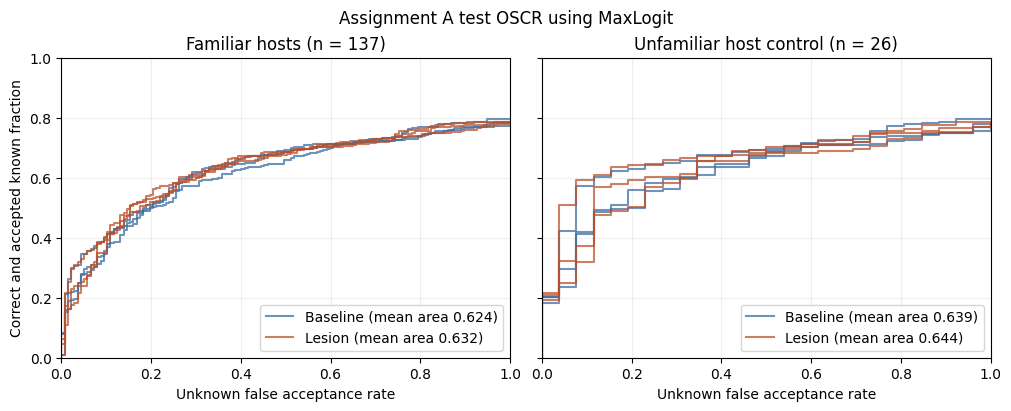

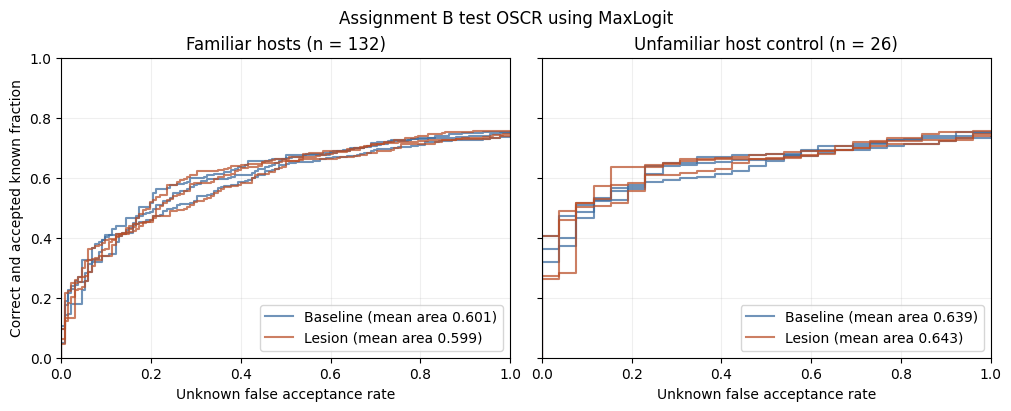

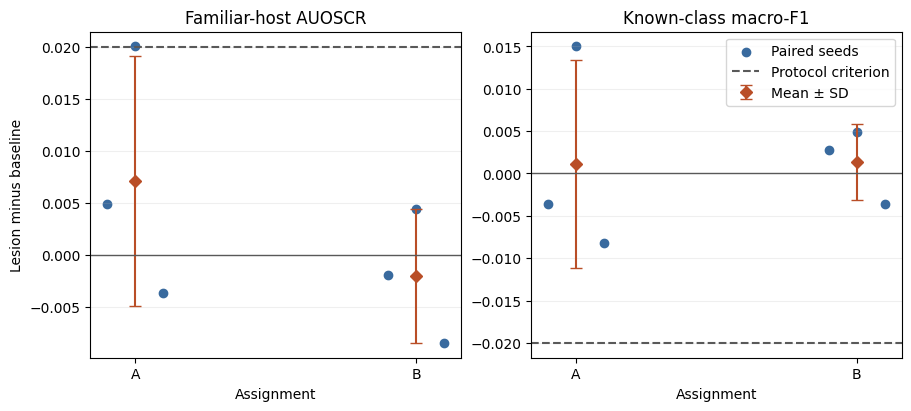

In [4]:
RUN_TEST = False

if RUN_TEST:
    from formal_evaluation import evaluate_test

    evaluate_test(MANIFEST_PATH, DATA_ROOT, CHECKPOINT_DIR, EVALUATION_DIR,
                  protocol_path=PROTOCOL_PATH)

results_path = EVALUATION_DIR / "test_results.json"
print(f"Frozen test results: {'available' if results_path.is_file() else 'pending'}")

if results_path.is_file():
    import matplotlib.pyplot as plt
    from formal_evaluation import plot_oscr, plot_paired_differences, summary_rows

    results = json.loads(results_path.read_text())
    print(f"Primary score: {results['primary_score']}")
    print(f"Both assignments meet all protocol criteria: {results['supports_hypothesis']}")
    metrics = {
        "known_macro_f1": "Known macro-F1",
        "known_accuracy": "Known accuracy",
        "known_acceptance": "Known acceptance",
        "known_correct_acceptance": "Known correct and accepted",
        "familiar_host/auoscr": "Familiar-host AUOSCR",
        "familiar_host/unknown_auroc": "Familiar-host unknown AUROC",
        "familiar_host/unknown_false_acceptance": "Familiar-host unknown false acceptance",
        "unfamiliar_host/auoscr": "Unfamiliar-host AUOSCR",
        "unfamiliar_host/unknown_auroc": "Unfamiliar-host unknown AUROC",
        "unfamiliar_host/unknown_false_acceptance": "Unfamiliar-host unknown false acceptance",
    }
    table = ["| Assignment | Metric | Baseline mean ± SD | Lesion mean ± SD | Paired difference mean ± SD |",
             "|---|---|---:|---:|---:|"]
    for row in summary_rows(results):
        if row["metric"] not in metrics:
            continue
        values = [f"{row[key + '_mean']:.4f} ± {row[key + '_sd']:.4f}"
                  for key in ("baseline", "lesion", "paired_difference")]
        table.append(f"| {row['assignment']} | {metrics[row['metric']]} | " + " | ".join(values) + " |")
    display(Markdown("\n".join(table)))
    for assignment in protocol["assignments"]:
        plot_oscr(results, assignment)
    plot_paired_differences(results)
    plt.show()

## Formal test interpretation

Validation selected MaxLogit and a matched learning rate of 0.0001 in both assignments. Familiar-host test AUOSCR changed from 0.6245 to 0.6316 in assignment A and from 0.6007 to 0.5987 in assignment B. The paired mean gains were 0.0071 and -0.0020. Two of three seeds improved in A and one of three improved in B. Both assignments met the known-class macro-F1 tolerance. Neither reached the prespecified mean AUOSCR gain of 0.02.

At the thresholds calibrated on known validation images, the familiar-host false-acceptance rate averaged 82.48% for the baseline and 82.97% for lesion supervision in assignment A. The corresponding rates were 75.25% and 76.52% in assignment B. The main result therefore provides insufficient evidence that auxiliary lesion supervision consistently improved rejection under this protocol.